# 用 medaka-3d 的折射几何做 3D 重建，并和旧流程放进对比审阅 GUI

输入本仓库已有的三视角 SLEAP 输出（`sleap_output/<实验>/<ROUND_TAG>/{top_cam,side1_cam,side2_cam}.slp`），
用 **medaka-3d 仓库 `src/medaka3d/` 的代码**（直接 import，不复制）做每帧的跨视角配对和三角化；
**之后的步骤全部用本仓库旧流程的代码和参数**，这样和 `reconstruct_from_slp` 比较时，两边只有“逐帧重建”不同。

## 原理（一句话版）

每台相机 = 针孔 + Brown 畸变 + **平面折射界面**。像素先去畸变成空气中的射线，在界面用 Snell 定律折射
（顶部相机：空气→水 1 次；侧面相机：空气→4 mm 玻璃→水 2 次），得到**水中的真实光线**。
同一条鱼在 2–3 台相机里的射线应该交于一点：最小二乘求交点，**点到射线的 RMS 距离（mm）**就是残差。
每帧穷举所有跨视角配对（3 视角 36 种 / 2 视角 6 种），残差最小的就是答案。

## 流程

```
3 × <view>.slp ─步骤4─▶ 与旧流程相同的候选顺序（去假阳性 / 重复后按 score 排序），每视角取前 3 个
               ─步骤5─▶ medaka3d.correspond.reconstruct_multinode：逐帧跨视角配对（mouth + pectoral 打分）
               ─步骤6─▶ 三个节点 + 可见节点质心三角化，重投影 QC
               ─步骤7─▶ 旧流程：apply_cross_frame_tracking（8 / 80 mm，100 帧）→ _best.json / _3d.csv
                         → bind_topcam_id（top_cam.tracks.csv）→ _3d_identified.csv          ← 身份机制与旧流程完全相同
               ─步骤8─▶ medaka3d 自己的逐节点 3D 表（_nodes3d.csv / .npz）+ provenance
               ─步骤9-10▶ QC 图，与旧流程逐帧对比
               ─步骤11─▶ build_review_data → review_packages/<实验>/<ROUND_TAG>_medaka3d/（和旧流程同一套头尾修正）
               ─步骤12─▶ recon_compare：旧流程 vs medaka3d → compare_gui 的“3D 重建对比”模式
```

## 和旧流程比，哪里一样、哪里不同

| | 旧：`reconstruct_from_slp`（batch 参数） | 新：本 notebook |
|---|---|---|
| 标定文件 | `calibration_results/fixed_refractive_192x192x186/` | **同一套**（sha256 一致，步骤 3 校验） |
| 候选检测 | `load_2d_slp` 槽位顺序，每视角最多 6 个 | **同一顺序**，取前 3 个（medaka3d 固定 3 条鱼） |
| **逐帧跨视角配对** | `--num-candidates 6` 贪心三元组，单点（可见节点质心） | **穷举 36 / 6 种假设，多节点残差求和**（唯一不同的地方） |
| 连轨迹 | `apply_cross_frame_tracking` 8 / 80 / 100 | **同一个函数、同一组参数**（从 `RECONSTRUCT_ARGS` 解析，不会漂移） |
| 机器身份 | `bind_topcam_id` | **同一个** |
| 审阅包 / 头尾修正 | `build_review_data` | **同一个** |

> ⚠️ medaka-3d 的模块只在 K 组上验证过；它更强的 Viterbi 配对 / 片段缝合（`tools/c27…c34`）还没并入 `src/`，这里不用。
> 对比 GUI 里 B 版本的节点是审阅包用同一套标定重新三角化的（和 A 的 `initial` 同一层级）；medaka3d 自己三角化的节点在 `_nodes3d.csv`，两者差 < 0.1 mm。

**换实验**：只改步骤 1 的 `EXPERIMENT`。前提：三视角 `.slp`、`top_cam.tracks.csv`、旧流程的 3D（`batch_3d.done`）
和旧流程的审阅包（`build_packages` 做的代理视频 + `review_data.npz`）都已存在。

## 步骤 1 — 参数

- `EXPERIMENT` / `ROUND_TAG`：读 `sleap_output/<EXPERIMENT>/<ROUND_TAG>/<view>.slp`
- `MEDAKA3D_REPO`：`None` = 本仓库旁边的 `../medaka-3d`
- `FRAME_RANGE`：`None` = 全长；设成 `(start, end)` 可以快速试跑，输出标签会加 `_test<start>-<end>`，不会覆盖全长结果
- `ANCHOR` / `CORRESPONDENCE_NODES`：medaka3d 配对用的节点（`c13`：pectoral 更少缺失；`c18`：mouth + pectoral 让 2 视角帧区分度大增）
- `COMPARE_KIND`：对比 GUI 里两边都用的层级。`initial` = 纯三角化 + 头尾修正（推荐，两边同一层级）；`machine` = 再加两视角重三角化和去尖刺
- `VERSION_NAMES`：GUI 里两个版本的短名
- `OVERWRITE`：步骤 11、12 的结果已存在时是否重建（步骤 7、8 每次都重写，几分钟）

In [1]:
EXPERIMENT = "20260112_P_1_1_FCMC"
ROUND_TAG  = "s14_bottomup_3node_reviewed"

MEDAKA3D_REPO = None          # None = <本仓库>/../medaka-3d
FRAME_RANGE   = None          # None = 全长；或 (start, end)，end 不含

NODES                = ("mouth", "pectoral", "tail")   # 模型骨架，按顺序；会校验
ANCHOR               = "pectoral"
CORRESPONDENCE_NODES = ("mouth", "pectoral")

COMPARE_KIND  = "initial"                 # "initial" 或 "machine"
VERSION_NAMES = ("old", "medaka3d")       # 旧流程（参考）, 新

PATHS_CONFIG = None      # None = 自动选择 configs/paths.<用户名>.toml
REVIEW_ROOT  = None      # None = <data_root>/review_packages
OVERWRITE    = False

## 步骤 2 — 定位两个仓库、路径配置，导入 medaka3d 和桥接模块

- 输入：当前目录、`configs/paths.<用户名>.toml`、`../medaka-3d/src`
- 输出：`REPO`、`PATHS`、`M3D`、`SLP_DIR`、`OUT_DIR`（重建结果）、`REVIEW_A` / `REVIEW_B`（两个审阅包）
- medaka3d 只需要 numpy / scipy，本仓库 `.venv` 能直接 import；会打印两个仓库的 git 版本（写进 provenance）
- 桥接模块 `scripts/reconstruction_3d/medaka3d_bridge.py` 负责把 medaka3d 的逐帧结果交给旧流程的连轨迹 / 输出 / bind

In [2]:
import hashlib
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd


def find_repo_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "pyproject.toml").exists() and (d / "scripts" / "common" / "local_paths.py").exists():
            return d
    raise FileNotFoundError(f"找不到仓库根目录（从 {start} 向上没有 pyproject.toml）")


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.common.local_paths import load_local_paths
from scripts.sleap.batch_bottomup_track import default_paths_config
from scripts.reconstruction_3d.medaka3d_bridge import (
    batch_cli_args, best_by_frame, link_and_write, load_slot_ordered, slot_arrays, slot_ids, visible_centroid)

CFG = Path(PATHS_CONFIG) if PATHS_CONFIG else default_paths_config()
PATHS = load_local_paths(CFG)
if PATHS is None:
    raise FileNotFoundError(f"路径配置不存在：{CFG}")

M3D = Path(MEDAKA3D_REPO).resolve() if MEDAKA3D_REPO else (REPO.parent / "medaka-3d").resolve()
if not (M3D / "src" / "medaka3d" / "calib.py").is_file():
    raise FileNotFoundError(f"找不到 medaka-3d：{M3D}（设置 MEDAKA3D_REPO）")
if str(M3D / "src") not in sys.path:
    sys.path.insert(0, str(M3D / "src"))

import medaka3d
from medaka3d.calib import load_rig, triangulate
from medaka3d.correspond import reconstruct_multinode
from medaka3d.reconstruct import N_ANIMALS

if not Path(medaka3d.__file__).resolve().is_relative_to(M3D):
    raise ImportError(f"导入的 medaka3d 不是 {M3D} 里的：{medaka3d.__file__}")


def git_rev(path: Path, sub: str = ".") -> str:
    try:
        rev = subprocess.run(["git", "-C", str(path), "rev-parse", "--short", "HEAD"],
                             capture_output=True, text=True, check=True).stdout.strip()
        dirty = subprocess.run(["git", "-C", str(path), "status", "--porcelain", sub],
                               capture_output=True, text=True).stdout.strip()
        return rev + ("-dirty" if dirty else "")
    except (OSError, subprocess.CalledProcessError):
        return "unknown"


VIEWS = ("top_cam", "side1_cam", "side2_cam")
SLP_DIR = PATHS.sleap_output_dir / EXPERIMENT / ROUND_TAG
TOP_TRACKS = SLP_DIR / "top_cam.tracks.csv"
OUT_TAG = f"{ROUND_TAG}_medaka3d" + ("" if FRAME_RANGE is None else f"_test{FRAME_RANGE[0]}-{FRAME_RANGE[1]}")
OUT_DIR = PATHS.reconstruction_output_dir / EXPERIMENT / OUT_TAG
REVIEW_ROOT = Path(REVIEW_ROOT) if REVIEW_ROOT else PATHS.data_root / "review_packages"
REVIEW_A = REVIEW_ROOT / EXPERIMENT / ROUND_TAG          # 旧流程的审阅包（参考）
REVIEW_B = REVIEW_ROOT / EXPERIMENT / OUT_TAG            # 本 notebook 生成

missing = [p.name for p in [SLP_DIR / f"{v}.slp" for v in VIEWS] + [TOP_TRACKS] if not p.is_file()]
if missing:
    raise FileNotFoundError(f"{SLP_DIR} 缺少 {missing}（先跑 batch_pipeline.ipynb）")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("仓库根目录   :", REPO, " rev", git_rev(REPO, "scripts"))
print("medaka-3d    :", M3D, " rev", git_rev(M3D, "src"))
print("路径配置     :", CFG)
print("SLEAP 输入   :", SLP_DIR)
print("重建输出     :", OUT_DIR)
for name, p in (("审阅包 A（旧）", REVIEW_A / "review_data.npz"), ("代理视频", REVIEW_ROOT / EXPERIMENT / "proxy" / "proxy_manifest.json")):
    print(f"{name:12s}: {'✅' if p.exists() else '❌ 不存在（先跑 scripts.review.build_packages）'} {p.parent}")
print("Python       :", sys.executable)

仓库根目录   : C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline  rev d208c31-dirty
medaka-3d    : C:\Users\ReiterU\Documents\GitHub\medaka-3d  rev 50d56d0
路径配置     : C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline\configs\paths.ReiterU.toml
SLEAP 输入   : \\bucket.oist.jp\bucket\StephensU\medaka\sleap_output\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed
重建输出     : \\bucket.oist.jp\bucket\StephensU\medaka\reconstruction_3d\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed_medaka3d
审阅包 A（旧）    : ✅ \\bucket.oist.jp\bucket\StephensU\medaka\review_packages\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed
代理视频        : ✅ \\bucket.oist.jp\bucket\StephensU\medaka\review_packages\20260112_P_1_1_FCMC\proxy
Python       : C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline\.venv\Scripts\python.exe


## 步骤 3 — 读取折射标定，校验文件，打印相机参数

- 输入：`PATHS.calibration_model_dir`（`calibration_manifest.json` + 3 个相机 bundle）
- `load_rig` 会拒绝非 `refractive` backend、错误的视角顺序、非单位法向等，不会悄悄退回多项式模型
- 表 1：每台相机的折射层数、内参、相机到界面距离；表 2：标定自带的验证精度（mm）

In [3]:
CALIB_DIR = PATHS.calibration_model_dir
rig = load_rig(CALIB_DIR)
manifest = json.loads(rig.manifest.read_text(encoding="utf-8"))

for entry in manifest["model_files"]:
    digest = hashlib.sha256((CALIB_DIR / entry["path"]).read_bytes()).hexdigest()
    if digest != entry["sha256"]:
        raise ValueError(f"{entry['path']} 的 sha256 与 manifest 不一致")
print("标定目录:", CALIB_DIR, "（3 个 bundle sha256 校验通过）")
print("物理几何:", manifest["physical_geometry"])

cam_rows = []
for cam in rig.cameras:
    cam_rows.append({
        "view": cam.view, "camera": cam.name,
        "interfaces": "air→water" if cam.layer_count == 1 else "air→glass→water",
        "fx": round(cam.fx, 1), "fy": round(cam.fy, 1), "cx": round(cam.cx, 1), "cy": round(cam.cy, 1),
        "k1": round(cam.distortion[0], 4),
        "center_mm": np.round(cam.center, 1).tolist(),
        "interface_normal": np.round(cam.interface_normal, 3).tolist(),
        "cam_to_interface_mm": round(float((cam.interface_point - cam.center) @ cam.interface_normal), 1),
    })
display(pd.DataFrame(cam_rows))
display(pd.DataFrame(manifest["validation"]).T)

标定目录: C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline\calibration_results\fixed_refractive_192x192x186 （3 个 bundle sha256 校验通过）
物理几何: {'inside_x_span_mm': 192.0, 'inside_y_span_mm': 192.0, 'water_height_from_inside_floor_mm': 186.0, 'glass_thickness_mm': 4.0, 'validation_temperature_range_c': [25.0, 26.0], 'index_air': 1.0003, 'index_water': 1.3325, 'index_glass': 1.52, 'interfaces': 'fixed measured interfaces'}


,view,camera,interfaces,fx,fy,cx,cy,k1,center_mm,interface_normal,cam_to_interface_mm
0,top_cam,cam0,air→water,2136.0,2134.2,611.1,677.5,-0.2222,"[98.6, 111.4, 537.9]","[0.0, 0.0, -1.0]",351.9
1,side1_cam,cam1,air→glass→water,2205.3,2154.3,577.2,656.1,-0.2465,"[107.5, -374.2, 101.6]","[0.0, 1.0, 0.0]",370.2
2,side2_cam,cam2,air→glass→water,2161.7,2135.2,662.1,678.9,-0.2376,"[559.2, 113.0, 91.2]","[-1.0, 0.0, 0.0]",363.2


,n,rms_mm,median_mm,p95_mm,poses
training_point_to_ray,16392.0,0.469655,0.224751,0.662252,NaN
heldout_wet10_point_to_ray,2100.0,0.236715,0.168078,0.448029,NaN
heldout_wet20_point_to_ray,1440.0,0.429767,0.302550,0.676858,NaN
heldout_rigid_three_view_kabsch,NaN,0.792225,0.543233,1.563370,13.0


## 步骤 4 — 读三个视角的 `.slp`（与旧流程相同的候选顺序）

- `load_slot_ordered`：和 `load_2d_slp` / 审阅包完全相同的槽位顺序——先去掉假阳性和重复检测，再按实例 score 从高到低排。
  这样 medaka3d 用到的检测编号可以直接写进 `_best.json`，审阅包也能找到同一个检测
- 防串机位：`.slp` 记录的视频路径必须包含 `/<EXPERIMENT>/<view>/`
- 每视角每帧取前 3 个槽位；不足 3 个，或 3 个里有 `ANCHOR` 节点缺失的视角，这一帧不参与（另两台相机够就仍然重建）
- 第一次读完缓存到 `OUT_DIR/cache/<view>.slots.npz`；`.slp` 大小或修改时间变了会自动重读

In [4]:
CACHE_DIR = PATHS.reconstruction_output_dir / EXPERIMENT / f"{ROUND_TAG}_medaka3d" / "cache"   # 测试窗口也共用
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def read_view(view):
    slp = SLP_DIR / f"{view}.slp"
    stat = slp.stat()
    cache = CACHE_DIR / f"{view}.slots.npz"
    if cache.is_file():
        d = np.load(cache, allow_pickle=False)
        if int(d["slp_size"]) == stat.st_size and int(d["slp_mtime_ns"]) == stat.st_mtime_ns:
            if tuple(str(n) for n in d["nodes"]) != NODES:
                raise ValueError(f"{view}: 骨架 {list(d['nodes'])} 不是 {NODES}")
            return d["points"], d["counts"], True
    by_frame, nodes, n_frames = load_slot_ordered(slp, experiment=EXPERIMENT, view=view)
    if tuple(nodes) != NODES:
        raise ValueError(f"{slp.name}: 骨架 {nodes} 不是 {NODES}")
    points, counts = slot_arrays(by_frame, n_frames, len(NODES), N_ANIMALS)
    points = points.astype(np.float32)
    np.savez_compressed(cache, points=points, counts=counts, nodes=np.array(NODES),
                        slp_size=stat.st_size, slp_mtime_ns=stat.st_mtime_ns)
    return points, counts, False


t0 = time.time()
PTS, CNT = {}, {}
for view in VIEWS:
    PTS[view], CNT[view], cached = read_view(view)
    print(f"{view:10s} {len(CNT[view]):,} 帧  {int(CNT[view].sum()):,} 个候选  {'(缓存)' if cached else '(读 .slp)'}")
N_TOTAL = min(len(CNT[v]) for v in VIEWS)
if len({len(CNT[v]) for v in VIEWS}) > 1:
    print(f"⚠️ 三个视角帧数不同，取最短 {N_TOTAL}")

F0, F1 = (0, N_TOTAL) if FRAME_RANGE is None else (max(0, FRAME_RANGE[0]), min(N_TOTAL, FRAME_RANGE[1]))
N = F1 - F0
FRAMES = np.arange(F0, F1)
UV, COUNTS, COMPLETE = {}, {}, {}
for view in VIEWS:
    pts = PTS[view][F0:F1].astype(float)
    UV[view] = {node: pts[:, :, k] for k, node in enumerate(NODES)}
    COUNTS[view] = CNT[view][F0:F1]
    COMPLETE[view] = (COUNTS[view] >= N_ANIMALS) & np.isfinite(UV[view][ANCHOR]).all(axis=(1, 2))

stats = pd.DataFrame({
    view: {"候选 = 3": (COUNTS[view] == 3).mean(), "候选 > 3（取前 3）": (COUNTS[view] > 3).mean(),
           "候选 < 3（不参与）": (COUNTS[view] < 3).mean(),
           f"可用（≥3 且 {ANCHOR} 齐全）": COMPLETE[view].mean()} for view in VIEWS}).T
display(stats.style.format("{:.2%}"))
n_complete = sum(COMPLETE[v].astype(int) for v in VIEWS)
print(f"窗口 {F0}–{F1} ({N:,} 帧 = {N / 166:.0f} s)；3 视角可用 {np.mean(n_complete == 3):.2%}，"
      f"恰 2 视角 {np.mean(n_complete == 2):.2%}，<2 视角 {np.mean(n_complete < 2):.2%}   用时 {time.time() - t0:.0f} s")

top_cam    348,600 帧  1,040,518 个候选  (缓存)


side1_cam  348,600 帧  1,009,245 个候选  (缓存)


side2_cam  348,600 帧  1,017,938 个候选  (缓存)


,候选 = 3,候选 > 3（取前 3）,候选 < 3（不参与）,可用（≥3 且 pectoral 齐全）
top_cam,93.58%,2.61%,3.81%,96.19%
side1_cam,88.29%,0.80%,10.91%,89.09%
side2_cam,90.80%,0.83%,8.37%,91.63%


窗口 0–348600 (348,600 帧 = 2100 s)；3 视角可用 79.51%，恰 2 视角 18.14%，<2 视角 2.35%   用时 1 s


## 步骤 5 — medaka3d 跨视角配对 + 三角化（`reconstruct_multinode`）

- 每帧按“哪些视角可用”分组：3 视角 → 36 种配对假设，2 视角 → 6 种；<2 视角不重建
- 每种假设对 `CORRESPONDENCE_NODES` 每个节点做射线三角化，残差相加；取最小者
- 输出 `REC`：`xyz`（`ANCHOR`，帧×槽×3，mm）、`residual_mm`、`margin_mm`（第二名 − 第一名，越大越确定）、`source`（每个槽用了各视角第几个候选）、`n_views_used`
- 参考（medaka-3d 在 K_1_2 上）：正确三元组残差 ~1.3 mm，错误 ~15 mm；margin < 1 mm 的帧配对不可靠

In [5]:
t0 = time.time()
REC, TALLY = reconstruct_multinode(
    rig, EXPERIMENT, UV, COMPLETE, N, anchor=ANCHOR, nodes=tuple(CORRESPONDENCE_NODES))
res = REC.resolved
print(f"用时 {time.time() - t0:.0f} s")
print(f"重建成功帧 {res.mean():.2%}（3 视角 {np.mean(REC.n_views_used == 3):.2%}，2 视角 {np.mean(REC.n_views_used == 2):.2%}）")
print(f"多节点结果与只用 {ANCHOR} 不同的帧：{TALLY['changed_vs_anchor_only']:,} / {TALLY['frames']:,} "
      f"({TALLY['changed_vs_anchor_only'] / max(1, TALLY['frames']):.2%})")

summary_rows = {}
for k in (3, 2):
    m = REC.n_views_used == k
    if m.any():
        r, g = REC.residual_mm[m].ravel(), REC.margin_mm[m]
        summary_rows[f"{k} 视角"] = {
            "帧数": int(m.sum()), "残差 中位 mm": np.nanmedian(r), "残差 p95 mm": np.nanpercentile(r, 95),
            "margin 中位 mm": np.nanmedian(g), "margin p1 mm": np.nanpercentile(g, 1), "margin < 1 mm": np.mean(g < 1.0)}
display(pd.DataFrame(summary_rows).T.style.format({"帧数": "{:,.0f}", "margin < 1 mm": "{:.2%}"}, precision=3))

用时 27 s
重建成功帧 97.65%（3 视角 79.51%，2 视角 18.14%）
多节点结果与只用 pectoral 不同的帧：947 / 340,410 (0.28%)


,帧数,残差 中位 mm,残差 p95 mm,margin 中位 mm,margin p1 mm,margin < 1 mm
3 视角,"277,179",0.501,0.826,24.008,1.644,0.54%
2 视角,"63,231",0.290,0.616,27.792,0.100,4.28%


## 步骤 6 — 用选定配对三角化：三个节点 + 可见节点质心，重投影 QC

- 三个节点各自三角化（某节点缺失的视角只少一条射线，<2 条射线 → NaN）→ `XYZ[node]`
- **可见节点质心**：每个用到的检测先取有效节点的 2D 平均（与旧流程 `--use-visible-node-centroid` 同一定义），再三角化 → `XYZ_C`，交给步骤 7 的旧连轨迹函数
- 自检：`ANCHOR` 坐标应与 `REC.xyz` 完全一致；3D → 像素 → 射线 往返误差应 ≈ 0
- 重投影误差（px）：3D 点投回各相机，与 SLEAP 检测点的像素距离

In [6]:
def triangulate_used(pix_of_view):
    # pix_of_view(view, src) -> (N, 3, 2) pixels of the detections REC chose
    origins = np.zeros((N, N_ANIMALS, len(rig.views), 3))
    dirs = np.zeros_like(origins)
    valid = np.zeros((N, N_ANIMALS, len(rig.views)), dtype=bool)
    for c, view in enumerate(rig.views):
        src = REC.source[:, :, c].astype(np.int64)
        o, d = rig.camera(view).rays(pix_of_view(view, src))
        ok = np.isfinite(o).all(-1) & np.isfinite(d).all(-1) & (src >= 0)
        origins[:, :, c] = np.where(ok[..., None], o, 0.0)
        dirs[:, :, c] = np.where(ok[..., None], d, 0.0)
        valid[:, :, c] = ok
    xyz, rms = triangulate(origins, dirs, valid)
    xyz[~res] = np.nan
    return xyz, rms, valid.sum(-1)


def chosen(view, src, node=None):
    fi, si = np.nonzero(src >= 0)
    if node is None:
        allp = np.stack([UV[view][n] for n in NODES], axis=2)            # (N, 3, nodes, 2)
        out = np.full((N, N_ANIMALS, 2), np.nan)
        out[fi, si] = visible_centroid(allp[fi, src[fi, si]])
        return out
    out = np.full((N, N_ANIMALS, 2), np.nan)
    out[fi, si] = UV[view][node][fi, src[fi, si]]
    return out


XYZ, RMS, NRAYS = {}, {}, {}
for node in NODES:
    XYZ[node], RMS[node], NRAYS[node] = triangulate_used(lambda v, s, node=node: chosen(v, s, node))
XYZ_C, RMS_C, _ = triangulate_used(lambda v, s: chosen(v, s))

both = np.isfinite(XYZ[ANCHOR]).all(-1) & np.isfinite(REC.xyz).all(-1)
print(f"自检：{ANCHOR} 与 REC.xyz 最大差 {np.abs(XYZ[ANCHOR][both] - REC.xyz[both]).max():.2e} mm；"
      f"质心有 3D 的槽位 {np.isfinite(XYZ_C[res]).all(-1).mean():.2%}")

qc_rows = []
for c, view in enumerate(rig.views):
    cam = rig.camera(view)
    src = REC.source[:, :, c].astype(np.int64)
    for node in NODES:
        X = XYZ[node]
        uvp = cam.project(X)
        fi, si = np.nonzero((src >= 0) & np.isfinite(X).all(-1))
        err = np.linalg.norm(uvp[fi, si] - UV[view][node][fi, src[fi, si]], axis=-1)
        o, d = cam.rays(uvp[fi, si])
        off = X[fi, si] - o
        back = np.linalg.norm(off - np.sum(off * d, -1, keepdims=True) * d, axis=-1)
        qc_rows.append({"view": view, "node": node, "n": int(np.isfinite(err).sum()),
                        "重投影 中位 px": np.nanmedian(err), "重投影 p95 px": np.nanpercentile(err, 95),
                        "往返误差 max mm": np.nanmax(back)})
display(pd.DataFrame(qc_rows).style.format({"n": "{:,}", "往返误差 max mm": "{:.1e}"}, precision=2))
node_rows = {node: {"有 3D 的槽位比例": np.isfinite(XYZ[node][res]).all(-1).mean(),
                    "3 条射线比例": np.mean(NRAYS[node][res] == 3),
                    "残差 中位 mm": np.nanmedian(RMS[node][res]), "残差 p95 mm": np.nanpercentile(RMS[node][res], 95)}
             for node in NODES}
display(pd.DataFrame(node_rows).T.style.format(precision=3))

自检：pectoral 与 REC.xyz 最大差 0.00e+00 mm；质心有 3D 的槽位 100.00%


,view,node,n,重投影 中位 px,重投影 p95 px,往返误差 max mm
0,top_cam,mouth,"988,578",1.88,6.12,1.7e-13
1,top_cam,pectoral,"999,012",2.07,5.21,1.6e-13
2,top_cam,tail,"981,960",2.61,7.23,1.4e-13
3,side1_cam,mouth,"907,824",2.01,5.42,1.6e-13
4,side1_cam,pectoral,"928,454",2.35,5.59,1.5e-13
5,side1_cam,tail,"912,973",2.91,7.37,8.7e-09
6,side2_cam,mouth,"936,277",1.96,4.92,1.7e-12
7,side2_cam,pectoral,"946,355",2.23,5.12,1.1e-08
8,side2_cam,tail,"931,494",2.73,7.12,7.2e-09


,有 3D 的槽位比例,3 条射线比例,残差 中位 mm,残差 p95 mm
mouth,0.995,0.793,0.409,1.030
pectoral,1.000,0.814,0.468,0.971
tail,0.990,0.787,0.574,1.369


## 步骤 7 — 用旧流程的连轨迹和 bind 给 medaka3d 结果分配身份

- `batch_cli_args()`：用 `reconstruct_from_slp` 自己的解析器解析 batch 流程的 `RECONSTRUCT_ARGS`，参数和旧流程**逐个相同**（下面打印）
- `best_by_frame`：medaka3d 的逐帧结果 → 旧流程的 pre-link 格式（`xyz_bounds` 外的点同样丢弃；只有 2 视角的鱼标为 recovered）
- `link_and_write`：`apply_cross_frame_tracking` → `<tag>_best_pre_link.json`、`<tag>_best.json`、`<tag>_3d.csv`（同样的缺口填补）
  → `bind_topcam_id` → `<tag>_3d_identified.csv`（`final_fish_id`）。几分钟；每次运行都会重写这几个文件
- 结果表：每个 ID 的覆盖率、单帧跳变 > 20 mm 的次数（新旧对照）、bind 结果

In [7]:
ARGS = batch_cli_args(EXPERIMENT)
best = best_by_frame(FRAMES, XYZ_C, REC.residual_mm, REC.source, xyz_bounds=tuple(ARGS.xyz_bounds))
dropped = int((np.isfinite(XYZ_C).all(-1) & ~np.array([[np.isfinite(best[f]["groups"][lb]).all() for lb in "abc"]
                                                        for f in FRAMES.tolist()])).sum())
any_det = np.logical_or.reduce([COUNTS[v] > 0 for v in VIEWS])
print(f"pre-link: {len(best):,} 帧；xyz_bounds {ARGS.xyz_bounds} 外丢弃 {dropped} 个槽位")
t0 = time.time()
LINK = link_and_write(best, out_dir=OUT_DIR, tag=OUT_TAG, top_tracks_csv=TOP_TRACKS, calibration_dir=CALIB_DIR,
                      all_frames=FRAMES[any_det], args=ARGS,
                      source={"medaka3d_repo": str(M3D), "medaka3d_rev": git_rev(M3D, "src"),
                              "anchor": ANCHOR, "correspondence_nodes": list(CORRESPONDENCE_NODES)})
print(f"用时 {time.time() - t0:.0f} s；连轨迹参数 {({k: v for k, v in LINK['linking'].items() if v is not None})}")
FISH_ID = slot_ids(LINK["best_tracked"], FRAMES, N_ANIMALS)        # (N, 3)：每个槽的 ID 编号，-1 = 未连上


def jump_table(csv_path, label):
    g = pd.read_csv(csv_path, usecols=["frame", "fish_id", "X", "Y", "Z"])
    g = g[(g.frame >= F0) & (g.frame < F1)].sort_values(["fish_id", "frame"])
    rows = {}
    for fid, t in g.groupby("fish_id"):
        xyz = t[["X", "Y", "Z"]].to_numpy()
        ok = np.isfinite(xyz).all(1)
        step = np.linalg.norm(np.diff(xyz, axis=0), axis=1)
        adj = (np.diff(t.frame.to_numpy()) == 1) & ok[1:] & ok[:-1]
        rows[(label, fid)] = {"有位置的帧": ok.mean() * len(t) / N, "跳变 >20 mm": int((step[adj] > 20).sum()),
                              "跳变 >50 mm": int((step[adj] > 50).sum())}
    return rows


OLD_CSV = PATHS.reconstruction_output_dir / EXPERIMENT / ROUND_TAG / f"{ROUND_TAG}_3d.csv"
jt = jump_table(LINK["csv_3d"], VERSION_NAMES[1])
if OLD_CSV.is_file():
    jt.update(jump_table(OLD_CSV, VERSION_NAMES[0]))
display(pd.DataFrame(jt).T.style.format({"有位置的帧": "{:.2%}"}))
ident = pd.read_csv(LINK["csv_identified"], usecols=["fish_id", "final_fish_id", "bind_source"])
print("bind 来源：", ident.bind_source.value_counts(normalize=True).round(4).to_dict())
print("fish_id → final_fish_id：", ident.groupby("fish_id")["final_fish_id"].first().to_dict())

pre-link: 348,600 帧；xyz_bounds [-20.0, 220.0] 外丢弃 21 个槽位
[bridge] linking 348,600 frames ...


[bridge] wrote s14_bottomup_3node_reviewed_medaka3d_best.json, s14_bottomup_3node_reviewed_medaka3d_3d.csv


[bind] dropping 6 top identity keys below 500 frames


[bind] global 1-to-1 assignment geometry fish_id -> top identity key:
  ID_1: 11
  ID_2: 12
  ID_3: 13
[bind] 1020522/1045800 (97.6%) rows bound via top_cam_2d


[bind] wrote \\bucket.oist.jp\bucket\StephensU\medaka\reconstruction_3d\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed_medaka3d\s14_bottomup_3node_reviewed_medaka3d_3d_identified.csv
[bind] projection provenance: \\bucket.oist.jp\bucket\StephensU\medaka\reconstruction_3d\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed_medaka3d\s14_bottomup_3node_reviewed_medaka3d_3d_identified_projection_provenance.json
[bridge] wrote s14_bottomup_3node_reviewed_medaka3d_3d_identified.csv
用时 384 s；连轨迹参数 {'num_individuals': 3, 'max_jump_mm': 8.0, 'max_jump_hard_cap_mm': 80.0, 'max_gap_frames': 100, 'velocity_prediction_weight': 0.0, 'flow_weight': 0.0, 'acceleration_weight': 0.0, 'motion_uncertainty_growth_per_frame': 0.25, 'motion_history_frames': 2, 'source_hints_override_motion_gate': False}


bind 来源： {'top_cam_2d': 0.9758, 'geometry_only': 0.0242}
fish_id → final_fish_id： {'ID_1': 11, 'ID_2': 12, 'ID_3': 13}


## 步骤 8 — 写 medaka3d 自己的逐节点 3D 表

`OUT_DIR = reconstruction_3d/<EXPERIMENT>/<OUT_TAG>/`（步骤 7 的旧格式文件也在这里）

| 文件 | 内容 |
|---|---|
| `<OUT_TAG>_nodes3d.csv` | 每个重建成功帧 × 3 个槽一行：`frame, slot, fish_id`（步骤 7 的 ID）、`n_views_used, residual_mm, margin_mm`，每个节点 `{node}_x/y/z/rms_mm/n_rays`，质心 `centroid_x/y/z`，`{view}_slot`（用了该视角第几个候选，-1 = 未参与）|
| `<OUT_TAG>_nodes3d.npz` | 同样数据按 (帧, 槽, …) 数组 |
| `<OUT_TAG>_medaka3d_provenance.json` | 两个仓库的版本、标定、输入 `.slp`、参数和统计 |

In [8]:
csv_path = OUT_DIR / f"{OUT_TAG}_nodes3d.csv"
npz_path = OUT_DIR / f"{OUT_TAG}_nodes3d.npz"
prov_path = OUT_DIR / f"{OUT_TAG}_medaka3d_provenance.json"
fi, si = np.nonzero(np.broadcast_to(res[:, None], (N, N_ANIMALS)))
cols = {"frame": FRAMES[fi], "slot": si,
        "fish_id": np.where(FISH_ID[fi, si] >= 0, np.char.add("ID_", (FISH_ID[fi, si] + 1).astype(str)), ""),
        "n_views_used": REC.n_views_used[fi], "residual_mm": REC.residual_mm[fi, si], "margin_mm": REC.margin_mm[fi]}
for node in NODES:
    for a, axis in enumerate("xyz"):
        cols[f"{node}_{axis}"] = XYZ[node][fi, si, a]
    cols[f"{node}_rms_mm"] = RMS[node][fi, si]
    cols[f"{node}_n_rays"] = NRAYS[node][fi, si]
for a, axis in enumerate("xyz"):
    cols[f"centroid_{axis}"] = XYZ_C[fi, si, a]
for c, view in enumerate(rig.views):
    cols[f"{view}_slot"] = REC.source[fi, si, c]
t0 = time.time()
pd.DataFrame(cols).to_csv(csv_path, index=False, float_format="%.4f")
np.savez_compressed(npz_path, frames=FRAMES, fish_id=FISH_ID, source=REC.source, n_views_used=REC.n_views_used,
                    residual_mm=REC.residual_mm.astype(np.float32), margin_mm=REC.margin_mm.astype(np.float32),
                    xyz_centroid=XYZ_C.astype(np.float32),
                    **{f"xyz_{n}": XYZ[n].astype(np.float32) for n in NODES},
                    **{f"rms_{n}": RMS[n].astype(np.float32) for n in NODES})
prov = {
    "created": time.strftime("%Y-%m-%dT%H:%M:%S%z"),
    "notebook": "archive/notebooks/experiment_workflows/20260112_P_1_1_FCMC_medaka3d_refractive_3d.ipynb",
    "medaka3d_repo": str(M3D), "medaka3d_rev": git_rev(M3D, "src"), "pipeline_rev": git_rev(REPO, "scripts"),
    "experiment": EXPERIMENT, "round_tag": ROUND_TAG, "out_tag": OUT_TAG, "frame_range": [int(F0), int(F1)],
    "calibration_manifest": str(rig.manifest),
    "calibration_sha256": {e["path"]: e["sha256"] for e in manifest["model_files"]},
    "inputs": {v: {"path": str(SLP_DIR / f"{v}.slp"), "size": (SLP_DIR / f"{v}.slp").stat().st_size,
                   "mtime_ns": (SLP_DIR / f"{v}.slp").stat().st_mtime_ns} for v in VIEWS} | {"top_tracks": str(TOP_TRACKS)},
    "params": {"anchor": ANCHOR, "correspondence_nodes": list(CORRESPONDENCE_NODES),
               "candidates": "load_2d_slp slot order (false positives dropped, by score), first 3 per view",
               "linking": {k: v for k, v in LINK["linking"].items() if k != "source_id_hints_by_frame"}},
    "stats": {"resolved": float(res.mean()), "three_views": float(np.mean(REC.n_views_used == 3)),
              "two_views": float(np.mean(REC.n_views_used == 2)),
              "residual_median_mm": float(np.nanmedian(REC.residual_mm)),
              "margin_median_mm": float(np.nanmedian(REC.margin_mm)),
              "changed_vs_anchor_only": TALLY["changed_vs_anchor_only"]},
    "outputs": [str(csv_path), str(npz_path)] + [str(LINK[k]) for k in ("best_json", "csv_3d", "csv_identified")],
}
prov_path.write_text(json.dumps(prov, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"用时 {time.time() - t0:.0f} s")
for p in sorted(OUT_DIR.glob(f"{OUT_TAG}_*")):
    print(f"  {p.name:60s} {p.stat().st_size / 1e6:8.1f} MB")

用时 24 s
  s14_bottomup_3node_reviewed_medaka3d_3d.csv                      77.1 MB
  s14_bottomup_3node_reviewed_medaka3d_3d_identified.csv          119.5 MB
  s14_bottomup_3node_reviewed_medaka3d_3d_identified_projection_provenance.json      0.0 MB
  s14_bottomup_3node_reviewed_medaka3d_best.json                  337.2 MB
  s14_bottomup_3node_reviewed_medaka3d_best_pre_link.json         209.0 MB
  s14_bottomup_3node_reviewed_medaka3d_medaka3d_provenance.json      0.0 MB
  s14_bottomup_3node_reviewed_medaka3d_nodes3d.csv                168.7 MB
  s14_bottomup_3node_reviewed_medaka3d_nodes3d.npz                 57.6 MB
  s14_bottomup_3node_reviewed_medaka3d_qc.png                       0.2 MB
  s14_bottomup_3node_reviewed_medaka3d_reconstruction_provenance.json      0.0 MB


## 步骤 9 — QC 图

1. 点到射线残差（3 视角 / 2 视角）与 margin 分布：残差应集中在 ~1 mm；margin 越大越好
2. 每 10 秒的重建成功率与 3 视角比例：开头放鱼 / 操作期间会低
3. 视频中段 20 秒的质心轨迹（俯视 XY），颜色 = 步骤 7 的 ID
4. 每个 ID 的单帧步长分布（新 = 实线，旧 = 虚线）：右侧的长尾是跳变 / 身份交换

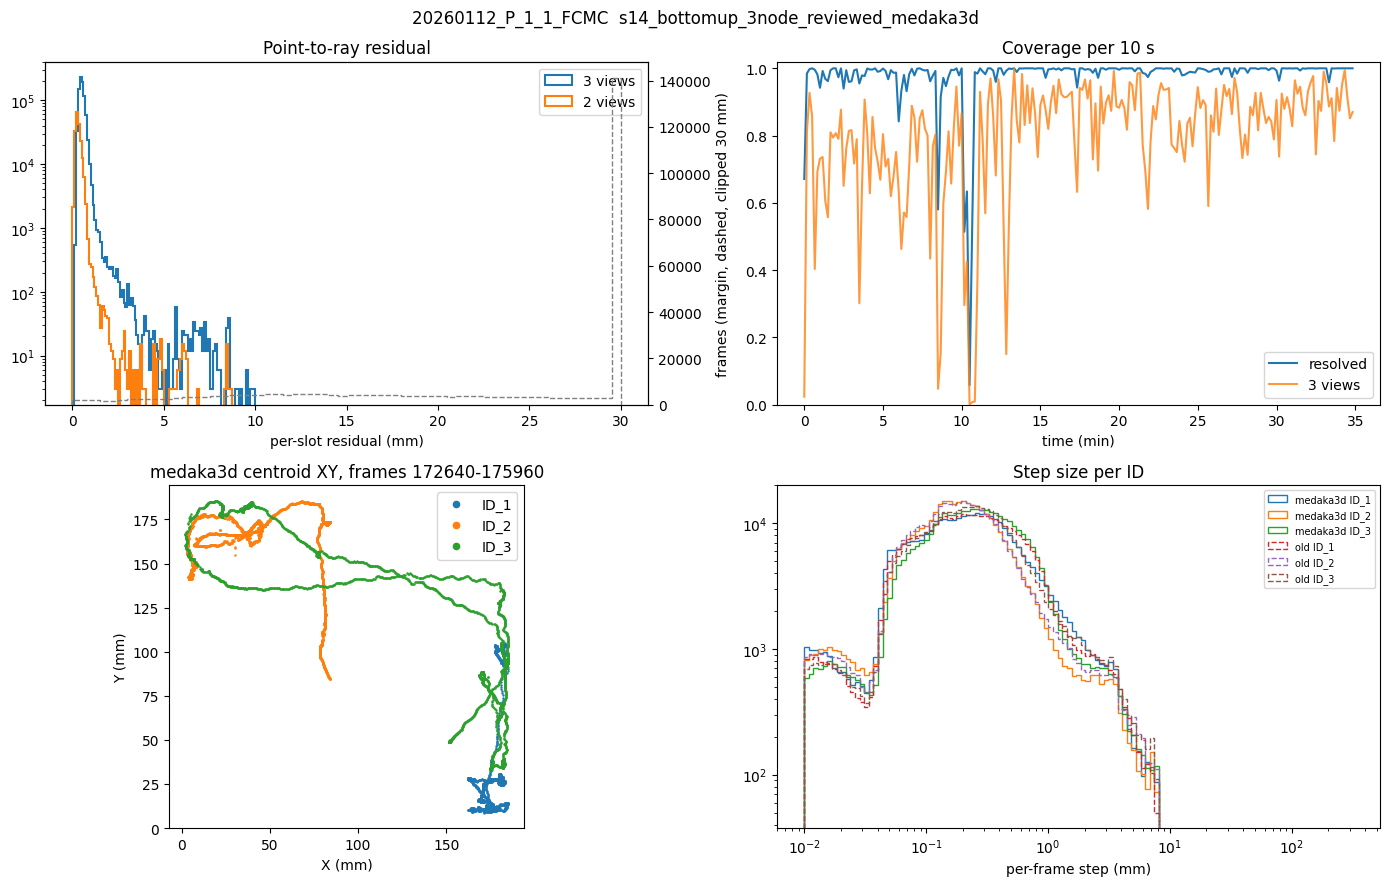

\\bucket.oist.jp\bucket\StephensU\medaka\reconstruction_3d\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed_medaka3d\s14_bottomup_3node_reviewed_medaka3d_qc.png


In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
a = ax[0, 0]
for k, color in ((3, "tab:blue"), (2, "tab:orange")):
    r = REC.residual_mm[REC.n_views_used == k].ravel()
    a.hist(r[np.isfinite(r)], bins=np.linspace(0, 10, 101), histtype="step", lw=1.5, color=color, label=f"{k} views")
a.set_yscale("log"); a.set_xlabel("per-slot residual (mm)"); a.set_title("Point-to-ray residual"); a.legend()
a2 = a.twinx()
g = REC.margin_mm[np.isfinite(REC.margin_mm)]
a2.hist(np.clip(g, 0, 30), bins=60, histtype="step", color="gray", ls="--")
a2.set_ylabel("frames (margin, dashed, clipped 30 mm)")

a = ax[0, 1]
bin_frames = 166 * 10
nb = N // bin_frames
if nb:
    t = (F0 + np.arange(nb) * bin_frames) / 166 / 60
    a.plot(t, res[: nb * bin_frames].reshape(nb, -1).mean(1), label="resolved")
    a.plot(t, (REC.n_views_used[: nb * bin_frames] == 3).reshape(nb, -1).mean(1), label="3 views", alpha=0.8)
a.set_xlabel("time (min)"); a.set_ylim(0, 1.02); a.set_title("Coverage per 10 s"); a.legend()

new3d = pd.read_csv(LINK["csv_3d"])
mid = F0 + N // 2
win3d = new3d[(new3d.frame >= mid - 1660) & (new3d.frame < mid + 1660)]
a = ax[1, 0]
for fid, gg in win3d.groupby("fish_id"):
    a.plot(gg.X, gg.Y, ".", ms=1.5, label=fid)
a.set_aspect("equal"); a.set_xlabel("X (mm)"); a.set_ylabel("Y (mm)"); a.legend(markerscale=6)
a.set_title(f"{VERSION_NAMES[1]} centroid XY, frames {mid - 1660}-{mid + 1660}")

a = ax[1, 1]
bins = np.logspace(-2, 2.5, 120)
for csv, ls, name in ((LINK["csv_3d"], "-", VERSION_NAMES[1]), (OLD_CSV, "--", VERSION_NAMES[0])):
    if not Path(csv).is_file():
        continue
    tab = new3d if csv == LINK["csv_3d"] else pd.read_csv(csv, usecols=["frame", "fish_id", "X", "Y", "Z"])
    tab = tab[(tab.frame >= F0) & (tab.frame < F1)].sort_values(["fish_id", "frame"])
    for fid, gg in tab.groupby("fish_id"):
        s = np.linalg.norm(np.diff(gg[["X", "Y", "Z"]].to_numpy(), axis=0), axis=1)
        s = s[(np.diff(gg.frame.to_numpy()) == 1) & np.isfinite(s)]
        a.hist(s, bins=bins, histtype="step", ls=ls, label=f"{name} {fid}")
a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("per-frame step (mm)"); a.set_title("Step size per ID")
a.legend(fontsize=7)
fig.suptitle(f"{EXPERIMENT}  {OUT_TAG}")
fig.tight_layout()
qc_png = OUT_DIR / f"{OUT_TAG}_qc.png"
fig.savefig(qc_png, dpi=110)
plt.show()
print(qc_png)

## 步骤 10 — 与旧流程逐帧对比（只比几何）

- 两边的质心（`<tag>_3d.csv`：都是可见节点质心）在同一帧都有 3 条鱼时，6 种排列里取平均距离最小的对应
- 判读：两边都对时应在 1–2 mm 内；大的差距 = 其中一边配对错（或旧流程用了第 4–6 个候选）
- 身份层面的差别（谁在哪一帧换错了鱼）在步骤 12 的对比 GUI 里看

In [10]:
from itertools import permutations

PERMS = list(permutations(range(N_ANIMALS)))


def per_frame(csv_path):
    t = pd.read_csv(csv_path, usecols=["frame", "fish_id", "X", "Y", "Z"])
    t = t[(t.frame >= F0) & (t.frame < F1)].dropna(subset=["X", "Y", "Z"]).sort_values(["frame", "fish_id"])
    t["rank"] = t.groupby("frame").cumcount()
    t = t[t["rank"] < N_ANIMALS]
    out = np.full((N, N_ANIMALS, 3), np.nan)
    out[t.frame.to_numpy() - F0, t["rank"].to_numpy()] = t[["X", "Y", "Z"]].to_numpy()
    return out


if not OLD_CSV.is_file():
    print(f"没有旧流程结果，跳过：{OLD_CSV}")
else:
    OLD, NEW = per_frame(OLD_CSV), per_frame(LINK["csv_3d"])
    old_ok, new_ok = np.isfinite(OLD).all(axis=(1, 2)), np.isfinite(NEW).all(axis=(1, 2))
    both = old_ok & new_ok
    display(pd.Series({f"{VERSION_NAMES[0]} 有 3 条": old_ok.mean(), f"{VERSION_NAMES[1]} 有 3 条": new_ok.mean(),
                       "两边都有": both.mean(), f"只有 {VERSION_NAMES[0]}": (old_ok & ~new_ok).mean(),
                       f"只有 {VERSION_NAMES[1]}": (new_ok & ~old_ok).mean()}).map("{:.2%}".format))
    A, B = NEW[both], OLD[both]
    d = np.linalg.norm(A[:, :, None, :] - B[:, None, :, :], axis=-1)
    tot = np.stack([d[:, [0, 1, 2], list(p)].sum(1) for p in PERMS], -1)
    bp = np.asarray(PERMS)[tot.argmin(-1)]
    per_fish = d[np.arange(len(A))[:, None], np.arange(3)[None, :], bp]
    worst = per_fish.max(1)
    print(f"每条鱼距离 中位 {np.median(per_fish):.2f} mm  p95 {np.percentile(per_fish, 95):.2f}  p99 {np.percentile(per_fish, 99):.2f}")
    print(f"平均偏移 (新−旧) XYZ = {np.round((A - B[np.arange(len(A))[:, None], bp]).reshape(-1, 3).mean(0), 2)} mm")
    display(pd.Series({f"三条鱼都 < {t} mm": np.mean(worst < t) for t in (2, 5, 10)}).map("{:.2%}".format))

old 有 3 条         99.94%
medaka3d 有 3 条    98.97%
两边都有              98.91%
只有 old             1.03%
只有 medaka3d        0.06%
dtype: str

每条鱼距离 中位 0.00 mm  p95 0.72  p99 3.78
平均偏移 (新−旧) XYZ = [-0.01  0.03  0.02] mm


三条鱼都 < 2 mm     96.30%
三条鱼都 < 5 mm     98.62%
三条鱼都 < 10 mm    99.60%
dtype: str

## 步骤 11 — 为 medaka3d 结果建审阅包（和旧流程同一个 `build_review_data`）

- 输入：步骤 7 的 `_best.json` / `_3d.csv` / `_3d_identified.csv`，同一份 `.slp`，同一套标定
- 输出：`review_packages/<EXPERIMENT>/<OUT_TAG>/`（`review_data.npz`、`detections.npz`、`machine_risk.csv` …）
  ——头尾修正、节点补全、风险窗口全部和旧流程的审阅包同一套代码；代理视频共用 `<EXPERIMENT>/proxy/`
- 几分钟；已存在且 `OVERWRITE = False` 时跳过。会检查审阅包是不是用当前的 `_best.json` 建的（sha256），不一致会提醒

In [11]:
from scripts.review.review_data import build_review_data

proxy_ok = (REVIEW_ROOT / EXPERIMENT / "proxy" / "proxy_manifest.json").exists()
if not proxy_ok:
    print(f"⚠️ 没有代理视频 {REVIEW_ROOT / EXPERIMENT / 'proxy'}：审阅包可以建，但 GUI 需要先跑 scripts.review.build_packages")
from scripts.review.review_data import file_fingerprint

stale = False
if (REVIEW_B / "review_manifest.json").exists():
    built_from = json.loads((REVIEW_B / "review_manifest.json").read_text(encoding="utf-8"))["sources"]["best_json"]
    stale = built_from["sha256"] != file_fingerprint(Path(LINK["best_json"]))["sha256"]
if (REVIEW_B / "review_data.npz").exists() and not OVERWRITE:
    print(f"已存在，跳过（OVERWRITE=False）：{REVIEW_B}" +
          ("  ⚠️ 步骤 7 的结果变了，请设 OVERWRITE=True 重建" if stale else "  （与步骤 7 的 _best.json 一致）"))
else:
    t0 = time.time()
    review_manifest = build_review_data(EXPERIMENT, OUT_TAG, slp_dir=SLP_DIR, recon_dir=OUT_DIR, out_dir=REVIEW_B,
                                        calibration_dir=CALIB_DIR, fps=166.0, log=print)
    s = review_manifest["summary"]
    print(f"审阅包 {REVIEW_B}  ({time.time() - t0:.0f} s)：风险窗口 {s['risk_windows']}，头尾跳变 {s['head_tail_jumps']}，"
          f"并在一起的区间 {s['machine_intervals']}")

已存在，跳过（OVERWRITE=False）：\\bucket.oist.jp\bucket\StephensU\medaka\review_packages\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed_medaka3d  （与步骤 7 的 _best.json 一致）


## 步骤 12 — 生成“3D 重建对比”数据，打开对比审阅 GUI

两种情况，自动判断：

| | 已审阅完的实验（有 `versions.npz` 且 `ready_for_analysis`） | 没审阅的实验 |
|---|---|---|
| 版本 | **reviewed**（你审阅后的 `final`，参考 = 标准答案）、**old**（旧流程 `initial`）、**medaka3d**（`initial`） | **old**（参考）、**medaka3d** |
| 身份 | 参考的名字全程正确、不能改；old 和 medaka3d 在分析起点附近继承名字，之后各走各的轨迹 | 你在 GUI 里给 old 起名（1/2/3 选，4/5/6 起名），medaka3d 继承 |
| 分歧列表 | old 与审阅结果不同的地方 + medaka3d 与审阅结果不同的地方 | old 与 medaka3d 不同的地方，需要你逐条判定 A/B/W/O |
| 输出目录 | `<ROUND_TAG>/recon_reviewed_old_medaka3d/` | `<ROUND_TAG>/recon_vs_<OUT_TAG>/` |

- **注意（已审阅的情况）**：身份对错可以直接以审阅结果为准（每一帧都人工看过）。几何不完全公平：审阅是在 old 的结果上修正的，
  没被修改的地方 reviewed 就等于 old，所以 old 的 `position` / `nodes` 分歧会偏少
- `initial` 第一次要算一次（~1 分钟，缓存为各自文件夹里的 `initial_tracks.npz`）
- 名字（`recon_labels.csv`）和判定（`recon_verdicts.csv`）只写在输出目录里，不碰审阅记录 `human_events.csv`
- 表 1：分歧条目按类型统计；表 2（已审阅时）：分析起点之后，每种方法与审阅结果不一致的鱼-帧数，以及只有一方错 / 两方都错

In [3]:
from scripts.review.recon_compare import RECON_FILE, ReconState, build, default_out_dir, error_table, summary

if not (REVIEW_A / "review_data.npz").exists():
    raise FileNotFoundError(f"没有旧流程的审阅包 {REVIEW_A}（先跑 scripts.review.build_packages）")
summary_path = REVIEW_A / "reviewed_summary.json"
REVIEWED = ((REVIEW_A / "versions.npz").exists() and summary_path.exists()
            and json.loads(summary_path.read_text(encoding="utf-8")).get("ready_for_analysis", False))
if REVIEWED:
    folders, kinds, names = [REVIEW_A, REVIEW_A, REVIEW_B], ["final", COMPARE_KIND, COMPARE_KIND], ["reviewed", *VERSION_NAMES]
else:
    folders, kinds, names = [REVIEW_A, REVIEW_B], [COMPARE_KIND, COMPARE_KIND], list(VERSION_NAMES)
RECON_DIR = default_out_dir(folders, names)
print("模式：", "已审阅 → reviewed / old / medaka3d 三个版本" if REVIEWED else "未审阅 → old / medaka3d 两个版本")
if (RECON_DIR / RECON_FILE).exists() and not OVERWRITE:
    print(f"已存在，跳过（OVERWRITE=False）：{RECON_DIR}")
else:
    t0 = time.time()
    build(folders, kinds, RECON_DIR, names=names, log=print)
    print(f"生成 {RECON_DIR / RECON_FILE}  ({time.time() - t0:.0f} s)")
STATE = ReconState(REVIEW_A, RECON_DIR)
print("参考版本的名字：", dict(zip(STATE.ref_ids, STATE.labels)), "  其他版本在第", STATE.link_frame, "帧继承名字",
      "  分析起点：", STATE.analysis_start)
display(summary(STATE))
if REVIEWED:
    display(error_table(STATE))
py = Path(sys.executable)
print("\n打开对比审阅 GUI（在 PowerShell 里运行）：")
print(f'  cd "{REPO}"')
print(f'  & "{py}" -m scripts.review.compare_gui "{REVIEW_A}" --mode recon --recon-dir "{RECON_DIR}"')
print("导出某段对比视频（不开 GUI）：")
print(f'  & "{py}" -m scripts.review.compare_gui "{REVIEW_A}" --recon-dir "{RECON_DIR}" --clip 105000 105400 --tracker-identity')

模式： 已审阅 → reviewed / old / medaka3d 三个版本
已存在，跳过（OVERWRITE=False）：\\bucket.oist.jp\bucket\StephensU\medaka\review_packages\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed\recon_reviewed_old_medaka3d


参考版本的名字： {'F': 'F', 'M1': 'M1', 'M2': 'M2'}   其他版本在第 4152 帧继承名字   分析起点： 4152


,other,group,kind,entries,frames,max_mm,A right,B right,both wrong,both OK
0,medaka3d,coverage,only medaka3d,2,200,0.000000,0,0,0,0
1,medaka3d,coverage,only reviewed,37,10613,0.000000,0,0,0,0
2,medaka3d,geometry,nodes,1463,19168,48.975362,0,0,0,0
3,medaka3d,geometry,position,362,4317,195.213222,0,0,0,0
4,medaka3d,identity,swap,29,768659,309.063478,0,0,0,0
5,old,geometry,nodes,1360,13955,67.454168,0,0,0,0
6,old,geometry,position,356,2159,36.330972,0,0,0,0
7,old,identity,swap,36,656433,297.748949,0,0,0,0


,kind,old entries,old fish-frames,old %,medaka3d entries,medaka3d fish-frames,medaka3d %,only old,only medaka3d,both
0,nodes,1315,13353,1.292,1441,18973,1.836,4876,10496,8477
1,only medaka3d,0,0,0.000,0,0,0.000,0,0,0
2,only reviewed,0,0,0.000,34,9056,0.876,0,9056,0
3,position,303,1684,0.163,333,3021,0.292,863,2200,821
4,swap,36,656433,63.525,26,764197,73.954,77417,185181,579016



打开对比审阅 GUI（在 PowerShell 里运行）：
  cd "C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline"
  & "C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline\.venv\Scripts\python.exe" -m scripts.review.compare_gui "\\bucket.oist.jp\bucket\StephensU\medaka\review_packages\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed" --mode recon --recon-dir "\\bucket.oist.jp\bucket\StephensU\medaka\review_packages\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed\recon_reviewed_old_medaka3d"
导出某段对比视频（不开 GUI）：
  & "C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline\.venv\Scripts\python.exe" -m scripts.review.compare_gui "\\bucket.oist.jp\bucket\StephensU\medaka\review_packages\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed" --recon-dir "\\bucket.oist.jp\bucket\StephensU\medaka\review_packages\20260112_P_1_1_FCMC\s14_bottomup_3node_reviewed\recon_reviewed_old_medaka3d" --clip 105000 105400 --tracker-identity


## 对比审阅 GUI 怎么用（“3D 重建对比”模式）

不带 `--mode` 打开时，如果文件夹里有好几种对比数据，会先弹窗让你选。快捷键在任何控件有焦点时都有效。

| 操作 | 键 / 按钮 |
|---|---|
| 播放 / 暂停 | `Space` 或第二行的 **> Play** 按钮；速度用 `↑/↓` 或速度下拉框 |
| 前后一帧 / 一秒 | `←/→`、`Shift+←/→`，或按钮 `< frame`、`frame >`、`<< 1 s`、`1 s >>`；也可以在 “go to frame” 输入帧号 |
| 下一个 / 上一个分歧 | `N` / `P`（或按钮），或双击右侧列表；跳到一条分歧时，B 自动切换成这条分歧对应的版本 |
| 切换显示哪两个版本（三版本时） | `7` reviewed vs old，`8` reviewed vs medaka3d，`9` old vs medaka3d（或按钮） |
| 起名（只在未审阅的实验） | `1/2/3` 或点击选鱼，再按 `4/5/6` = F / M1 / M2 |
| 判定当前（选中的）分歧 | `A` = A 版本对，`B` = B 版本对，`W` = 都错，`O` = 都对；`Backspace` 清除；判定后自动跳到下一条 |
| 只看几何（逐帧匹配，隐藏身份差别） | `I` |
| 放大 / 导出视频 | `Z`、`E` |

- 每条分歧是**一段连续帧**（中间间隔 < 0.1 s 的会合并），一条只需判断一次
- 右侧筛选：类型、鱼、版本（三版本时）、“after analysis start”（默认只看分析起点之后）、速度、最小 mm
- 已审阅的实验，身份错误不用手动判定：表 2 直接给出每种方法错了多少